In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [194]:
names = ("Time","ARID","lat","lon","flux", "area")
data = pd.read_csv("data/ardata_304_tracked_2014.csv", header=None, names=names, index_col=0)
data.index=pd.to_datetime(data.index)

ARID
20110101TN13323     29
20110101TN15176      5
20110101TN22076     29
20110101TN25051      7
20110101TN32191    109
                  ... 
20111226TS17150      2
20111226TS21226      1
20111227TS18150      2
20111228TS18147     10
20111230TN08115      2
Length: 222, dtype: int64

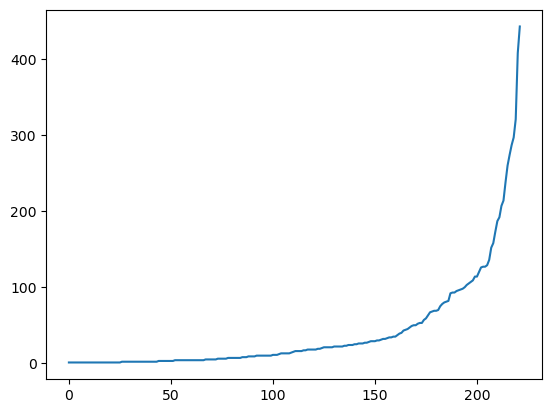

In [187]:
a = data[["ARID"]].groupby("ARID").value_counts(ascending=True, sort=True)
plt.plot(np.sort(a.values))
a

[Text(0.5, 0, 'Flux')]

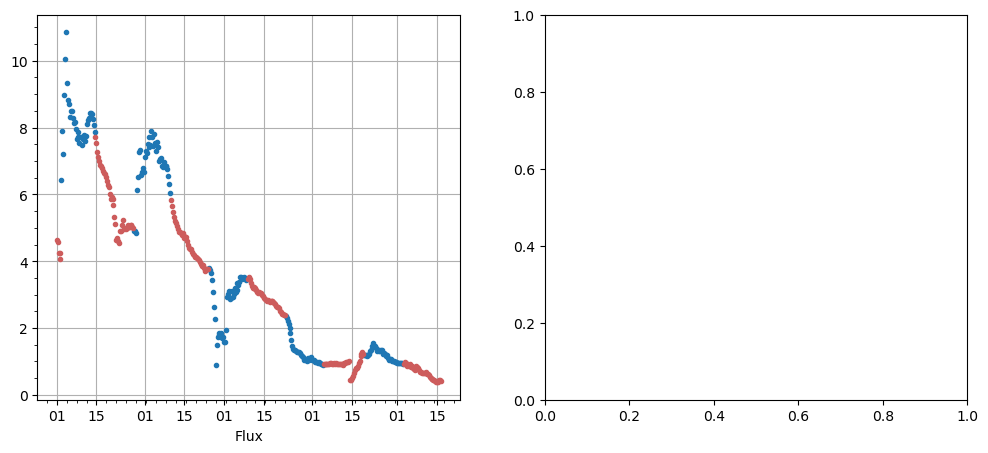

In [199]:
import time
import matplotlib.dates as mdates
from sunpy.coordinates.sun import L0
l0 = L0(data.index).deg
ars = np.unique(data.ARID.values)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))
_ars="20140101TS14072"
ind = data.ARID.values == _ars

in1 = (data.lon < l0+90) & (data.lon > l0-90)
ind = ind & in1
ax1.plot_date(data.index.values[ind], data.flux.values[ind]/1.0e22,".", label ="Near Side", color="tab:blue")

ind = data.ARID.values == _ars
in1 = (data.lon >l0+90) | (data.lon < l0-90)
ind = ind & in1

ax1.plot(data.index.values[ind], data.flux.values[ind]/1.0e22,".", label ="Farside Side", color="indianred")
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d'))
ax1.grid()
ax1.minorticks_on()
ax1.set(xlabel="Flux")

# _ax1 = ax1.twiny()
# _ax1.spines["bottom"].set_position(("axes",-0.1))
# _ax1.tick_params(top=False, bottom=True)
# _ax1.xaxis.set_ticks_position("bottom")
# _ax1.set_xlim(ax1.get_xlim())
# # _ax.set_xticks(ax1.get_xticks())
# _ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
# _ax.set_xticklabels(ax1.get_xticklabels())

# ar304 = pd.read_csv("data/ar_test.txt", header=None, delim_whitespace=True)

# im = plt.imread("/Users/bjha/Pictures/Screenshots/Screenshot 2023-09-05 at 1.16.08 AM.png")
# ax2.imshow(im)
# ax2.axis("off")


# ax = plt.gca()
# locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
# formatter = mdates.ConciseDateFormatter(locator)
# ax.xaxis.set_major_locator(locator)
# ax.xaxis.set_major_formatter(formatter)

# plt.legend()

In [193]:
ind

Time
2011-01-01 00:00:00    False
2011-01-01 00:00:00    False
2011-01-01 00:00:00    False
2011-01-01 00:00:00    False
2011-01-01 00:00:00    False
                       ...  
2011-12-31 16:00:00    False
2011-12-31 16:00:00    False
2011-12-31 16:00:00    False
2011-12-31 16:00:00    False
2011-12-31 16:00:00    False
Name: lon, Length: 9248, dtype: bool

In [72]:
import h5py as h5
fl = h5.File("/Users/bjha/Documents/test_out/ARmap_20140310_0000.h5")

In [87]:
fl["ars/10001/lat"][()]

-17.816

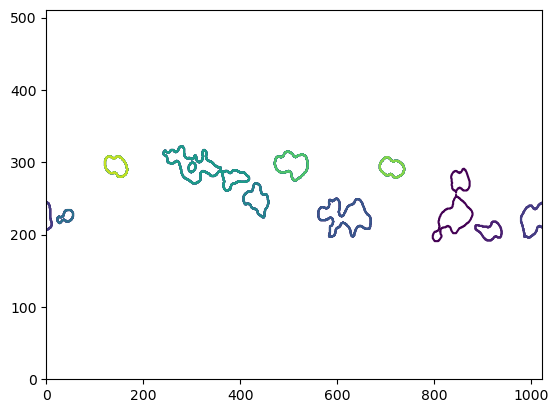

In [92]:
plt.contour(armap, levels = np.unique(armap)[1:])